# Assignment 4 — Problem 1
## Logistic regression: custom gradient descent and exact Newton method
Executed using the supplied `marks.txt`. The notebook includes parts (a)–(d), mathematical explanations, all code, outputs, figures, and reproducibility details.


## Setup and reproducibility
Place `marks.txt` beside this notebook and run cells in order. Dependencies are NumPy, pandas, SciPy, Matplotlib, and IPython. If needed, install them in a separate cell using `%pip install numpy pandas scipy matplotlib ipython`.

The custom methods use the summed objective, zero initialization, and the same stopping rule in standardized coordinates. TNC is used only as an external reference. Timings exclude data loading, plotting, and file export.

In [1]:
# Import libraries
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit
from scipy.optimize import fmin_tnc

%matplotlib inline

np.set_printoptions(precision=8, suppress=True)

OUTPUT = Path("results")
OUTPUT.mkdir(exist_ok=True)

## Data convention and parameter coordinates
The course file has 100 numerical rows and no header. The reference PDF calls `pd.read_csv` without `header=None`; its first row is consequently interpreted as a header, leaving **99 observations**. We deliberately reproduce that convention. This is a reproduction choice, not a recommendation to discard observations in a new study.

Let $x_{ij}$ be a score, with training mean $m_j$ and standard deviation $s_j$. We optimize using $z_{ij}=(x_{ij}-m_j)/s_j$. If standardized parameters are $(a,v_1,v_2)$, conversion back is

$$
w_j=v_j/s_j,\qquad b=a-\sum_jm_jv_j/s_j.
$$

Thus the logits and unregularized objective are unchanged. Standardization changes the gradient-descent path, not the optimum. The parameter order throughout is intercept, first slope, second slope.

In [2]:
# Load and prepare the data
data_path = Path("marks.txt")

print("Current folder:", Path.cwd())
print("Data file found:", data_path.exists())

if not data_path.exists():
    raise FileNotFoundError(
        "Upload marks.txt to the notebook's current folder."
    )

# Deliberately matches the reference PDF.
data = pd.read_csv(data_path).to_numpy(dtype=float)

features = data[:, :2]
y = data[:, 2]

if not np.isfinite(data).all():
    raise ValueError("The data contain missing or nonfinite values.")

if not np.isin(y, [0, 1]).all():
    raise ValueError("The response must contain only 0 and 1.")

# Original feature units.
X = np.column_stack([
    np.ones(len(y)),
    features
])

# Standardization improves gradient-descent conditioning.
feature_mean = features.mean(axis=0)
feature_std = features.std(axis=0)

if np.any(feature_std == 0):
    raise ValueError("A feature has zero standard deviation.")

Z = np.column_stack([
    np.ones(len(y)),
    (features - feature_mean) / feature_std
])

print("Number of observations:", len(y))
print("Original design matrix shape:", X.shape)
print("Standardized design matrix shape:", Z.shape)

display(
    pd.DataFrame(
        data,
        columns=["Exam 1", "Exam 2", "Admitted"]
    ).head()
)

Current folder: /workspace/work/assignment4_delivery
Data file found: True
Number of observations: 99
Original design matrix shape: (99, 3)
Standardized design matrix shape: (99, 3)


,Exam 1,Exam 2,Admitted
0,30.286711,43.894998,0.0
1,35.847409,72.902198,0.0
2,60.182599,86.308552,1.0
3,79.032736,75.344376,1.0
4,45.083277,56.316372,0.0


In [3]:
def to_original(parameters):
    """Convert standardized logistic coefficients to original exam-score units.
    
    Parameters
    ----------
    parameters : array_like, shape (3,) or (k, 3)
        Finite coefficients ordered as intercept, first slope, second slope.
    
    Returns
    -------
    numpy.ndarray, shape (k, 3)
        Original-unit coefficients; a single input vector returns one row.
    
    Assumptions
    -----------
    The global feature_mean and feature_std contain the two training-feature
    means and positive population standard deviations used to construct Z.
    """
    parameters = np.atleast_2d(parameters)

    weights = parameters[:, 1:] / feature_std
    intercept = parameters[:, 0] - weights @ feature_mean

    return np.column_stack([intercept, weights])


## Observed admissions data
The scatter plot distinguishes admitted and non-admitted applicants. The two exam scores are the predictors; admission is the binary response.

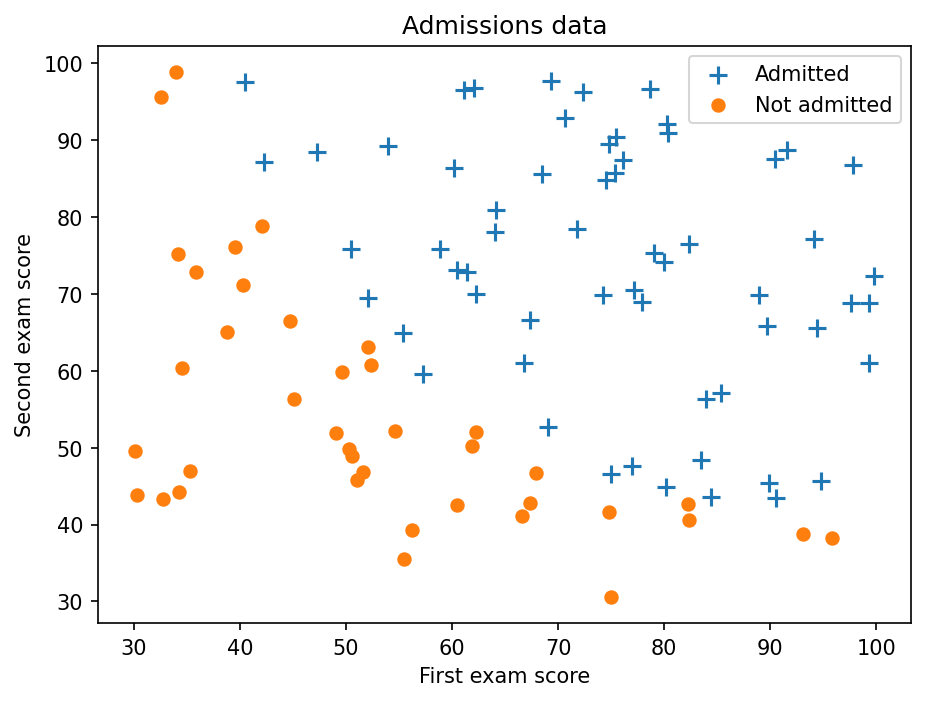

In [4]:
# Plot the observations
admitted = y == 1
not_admitted = y == 0

plt.figure(figsize=(7, 5))

plt.scatter(
    features[admitted, 0],
    features[admitted, 1],
    label="Admitted",
    marker="+",
    s=70
)

plt.scatter(
    features[not_admitted, 0],
    features[not_admitted, 1],
    label="Not admitted",
    marker="o",
    s=35
)

plt.xlabel("First exam score")
plt.ylabel("Second exam score")
plt.title("Admissions data")
plt.legend()
plt.show()

## Objective, gradient, and exact Hessian

Let $A$ denote either the original design matrix $X$ or standardized design matrix $Z$, including the intercept column. Define the linear predictor and predicted probability by

$$
q_i=a_i^T\theta,\qquad p_i=\sigma(q_i)=\frac{1}{1+e^{-q_i}}.
$$

Assuming conditional independence, the likelihood is the product of the probabilities assigned to the observed labels. Taking logarithms and negating converts maximum likelihood into minimization:

$$
f(\theta)=-\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].
$$

Substituting the sigmoid expression gives the equivalent form

$$
f(\theta)=\sum_i\left[\log(1+e^{q_i})-y_iq_i\right].
$$

The implementation evaluates this expression with `logaddexp` for numerical stability. The loss is a sum, not an average, and includes no regularization penalty.

### Deriving the gradient

First, the sigmoid derivative is

$$
\sigma'(q)=\sigma(q)\left[1-\sigma(q)\right].
$$

For one loss contribution $f_i$, differentiating with respect to its predicted probability gives

$$
\frac{\partial f_i}{\partial p_i}
=-\frac{y_i}{p_i}+\frac{1-y_i}{1-p_i}.
$$

Since $\partial p_i/\partial q_i=p_i(1-p_i)$, the chain rule simplifies this derivative to

$$
\frac{\partial f_i}{\partial q_i}
=-y_i(1-p_i)+(1-y_i)p_i=p_i-y_i.
$$

Next, $\partial q_i/\partial\theta_j=a_{ij}$. Applying the chain rule and summing across observations yields the coordinate derivative

$$
\frac{\partial f}{\partial\theta_j}
=\sum_i(p_i-y_i)a_{ij}.
$$

Collecting these derivatives into a vector gives

$$
\boxed{g=\nabla f(\theta)=A^T(p-y)}.
$$

### Deriving the exact Hessian

Differentiating the probability with respect to coefficient $\theta_k$ gives

$$
\frac{\partial p_i}{\partial\theta_k}
=p_i(1-p_i)a_{ik}.
$$

Differentiating the coordinate gradient once more therefore yields

$$
\frac{\partial^2f}{\partial\theta_j\partial\theta_k}
=\sum_i p_i(1-p_i)a_{ij}a_{ik}.
$$

Define $S=\operatorname{diag}\left(p_i(1-p_i)\right)$. The matrix form is

$$
\boxed{H=\nabla^2f(\theta)=A^TSA}.
$$

This is the **exact analytic Hessian derived in lecture**, not a finite-difference or quasi-Newton approximation. For finite parameters it is positive semidefinite; it is positive definite if $A$ has full column rank. Convexity alone does not guarantee a finite optimum for completely separable data.


In [5]:
# Define the loss, gradient, and exact Hessian
def loss(theta, A, y):
    """Evaluate the summed, unregularized logistic negative log-likelihood.
    
    Parameters
    ----------
    theta : numpy.ndarray, shape (d,)
        Finite model coefficients, including the intercept coefficient.
    A : numpy.ndarray, shape (n, d)
        Finite design matrix, including a column of ones for the intercept.
    y : numpy.ndarray, shape (n,)
        Binary labels in {0, 1}; dimensions must agree with A and theta.
    
    Returns
    -------
    float
        Sum of binary cross-entropy losses, not their average.
    
    Notes
    -----
    logaddexp avoids exponent overflow. No regularization is included.
    """
    z = A @ theta
    return float(np.logaddexp(0, z).sum() - y @ z)


def gradient(theta, A, y):
    """Compute the exact analytic gradient of the summed logistic loss.
    
    Parameters
    ----------
    theta : numpy.ndarray, shape (d,)
        Finite model coefficients.
    A : numpy.ndarray, shape (n, d)
        Finite design matrix with an intercept column.
    y : numpy.ndarray, shape (n,)
        Binary labels; dimensions must match A and theta.
    
    Returns
    -------
    numpy.ndarray, shape (d,)
        A.T @ (sigmoid(A @ theta) - y), with no regularization term.
    """
    probabilities = expit(A @ theta)
    return A.T @ (probabilities - y)


def hessian(theta, A, y):
    """Compute the exact analytic Hessian H = A.T @ diag(p*(1-p)) @ A.
    
    Parameters
    ----------
    theta : numpy.ndarray, shape (d,)
        Finite model coefficients.
    A : numpy.ndarray, shape (n, d)
        Finite design matrix with an intercept column.
    y : numpy.ndarray, shape (n,)
        Binary labels. Retained for a common interface; H does not use y.
    
    Returns
    -------
    numpy.ndarray, shape (d, d)
        Exact symmetric Hessian, evaluated without an n-by-n diagonal array.
    
    Assumptions
    -----------
    Dimensions agree. Full column rank and nonsaturated probabilities are
    needed for a nonsingular numerical Newton system. No penalty is added.
    """
    z = A @ theta

    # Equivalent to p * (1 - p).
    variance = expit(z) * expit(-z)

    return A.T @ (variance[:, None] * A)


## Part (a): gradient descent with backtracking
The gradient-descent direction is $d_k=-g_k$. If $g_k\ne0$, then $g_k^Td_k=-\|g_k\|^2<0$, so it is a descent direction.

To choose a step, begin with $\alpha=1$ and repeatedly replace $\alpha$ by $0.5\alpha$ until

$$
\boxed{f(\theta_k+\alpha d_k)\le f(\theta_k)+10^{-4}\alpha g_k^Td_k}.
$$

This is the Armijo sufficient-decrease condition. In the lecture's notation the Armijo fraction is $10^{-4}$, the contraction factor is $0.5$, and the trial step is $\alpha$.

In [6]:
# (a) Backtracking line search
def backtracking(
    theta,
    direction,
    A,
    y,
    current_loss,
    g,
    c=1e-4,
    shrink=0.5,
    max_backtracks=80
):
    """Select a step satisfying Armijo sufficient decrease.
    
    Parameters
    ----------
    theta, direction, g : numpy.ndarray, shape (d,)
        Current coefficients, descent direction, and current gradient.
    A : numpy.ndarray, shape (n, d)
        Finite design matrix with an intercept column.
    y : numpy.ndarray, shape (n,)
        Binary labels with compatible dimensions.
    current_loss : float
        loss(theta, A, y), using the same summed objective.
    c : float, default 1e-4
        Armijo fraction, satisfying 0 < c < 0.5.
    shrink : float, default 0.5
        Step contraction factor, satisfying 0 < shrink < 1.
    max_backtracks : int, default 80
        Positive maximum number of trial steps; the first trial is alpha=1.
    
    Returns
    -------
    (alpha, candidate_loss, reductions) : tuple
        Accepted positive step, its objective, and number of contractions.
    
    Raises
    ------
    ValueError
        If g @ direction is nonnegative.
    RuntimeError
        If none of the allowed trials satisfies Armijo.
    
    Assumptions
    -----------
    Inputs have matching dimensions; g and current_loss refer to theta.
    """
    directional_derivative = float(g @ direction)

    if directional_derivative >= 0:
        raise ValueError("The direction is not a descent direction.")

    alpha = 1.0

    for reductions in range(max_backtracks):
        candidate = theta + alpha * direction
        candidate_loss = loss(candidate, A, y)

        armijo_bound = (
            current_loss
            + c * alpha * directional_derivative
        )

        if (
            np.isfinite(candidate_loss)
            and candidate_loss <= armijo_bound
        ):
            return alpha, candidate_loss, reductions

        alpha *= shrink

    raise RuntimeError(
        "Backtracking could not find an acceptable step."
    )


## Parts (a) and (d): custom descent and exact Newton updates
The accepted update is $\theta_{k+1}=\theta_k+\alpha_k d_k$.

For Newton, a second-order model is $f(\theta_k)+g_k^Td+\tfrac12d^TH_kd$. Its first-order condition gives

$$
\boxed{H_kd_k=-g_k}.
$$

The code solves this system with `np.linalg.solve` rather than explicitly forming an inverse. It uses the exact Hessian; the lecture's QR-based implementation is an alternative way to solve the same Newton system.

Every run starts at zero, and stops when $\|g_k\|_\infty\le10^{-6}$ in standardized coordinates, or returns an explicit failure status. The complete three-dimensional path, losses, accepted steps, and backtracking counts are retained.

In [7]:
# Part (a) and (d): Custom optimizers
# This function implements: Gradient descent with backtracking/ Newton’s method with full steps/Newton’s method with backtracking
def optimize(
    A,
    y,
    method="gd",
    line_search=True,
    initial=None,
    tol=1e-6,
    maxiter=20000
):
    """Minimize summed logistic loss by custom gradient descent or Newton.
    
    Parameters
    ----------
    A : numpy.ndarray, shape (n, d)
        Finite design matrix, optionally standardized; includes intercept.
    y : numpy.ndarray, shape (n,)
        Binary labels with compatible dimensions.
    method : {'gd', 'newton'}
        Negative-gradient direction or exact-Hessian Newton direction.
    line_search : bool
        Use Armijo backtracking if True; otherwise take alpha=1.
    initial : array_like, shape (d,), or None
        Starting coefficients in A's coordinates; None means all zeros.
    tol : positive float
        Stop when the gradient infinity norm in A's coordinates is <= tol.
    maxiter : positive int
        Maximum number of accepted parameter updates.
    
    Returns
    -------
    dict
        theta: final coefficients; path: initial and all accepted vectors;
        losses: objective for every vector; step_sizes and backtracks: one
        value per accepted update; status: termination reason; steps: updates.
    
    Assumptions
    -----------
    A and y have the stated dimensions. Newton requires a solvable Hessian.
    Numerical failures return a status rather than a fabricated solution.
    No built-in optimizer or regularization is used in this routine.
    """
    theta = (
        np.zeros(A.shape[1])
        if initial is None
        else np.array(initial, dtype=float).copy()
    )

    path = [theta.copy()]
    losses = [loss(theta, A, y)]
    step_sizes = []
    backtracks = []

    status = "maximum iterations"

    for _ in range(maxiter):
        g = gradient(theta, A, y)

        if np.linalg.norm(g, ord=np.inf) <= tol:
            status = "converged"
            break

        if method == "gd":
            direction = -g

        elif method == "newton":
            H = hessian(theta, A, y)

            try:
                # Solve H @ direction = -g.
                direction = np.linalg.solve(H, -g)

            except np.linalg.LinAlgError:
                status = "singular Hessian"
                break

        else:
            raise ValueError("Use method='gd' or method='newton'.")

        if (
            not np.all(np.isfinite(direction))
            or g @ direction >= 0
        ):
            status = "invalid descent direction"
            break

        if line_search:
            try:
                alpha, new_loss, reductions = backtracking(
                    theta=theta,
                    direction=direction,
                    A=A,
                    y=y,
                    current_loss=losses[-1],
                    g=g
                )

            except RuntimeError:
                status = "line search failed"
                break

        else:
            alpha = 1.0
            reductions = 0
            new_loss = loss(
                theta + direction,
                A,
                y
            )

        theta = theta + alpha * direction

        path.append(theta.copy())
        losses.append(new_loss)
        step_sizes.append(alpha)
        backtracks.append(reductions)

        if not np.isfinite(new_loss):
            status = "nonfinite loss"
            break

    # Handle convergence occurring exactly on the final allowed step.
    if (
        status == "maximum iterations"
        and np.linalg.norm(
            gradient(theta, A, y),
            ord=np.inf
        ) <= tol
    ):
        status = "converged"

    return {
        "theta": theta,
        "path": np.array(path),
        "losses": np.array(losses),
        "step_sizes": np.array(step_sizes),
        "backtracks": np.array(backtracks),
        "status": status,
        "steps": len(path) - 1
    }


## Independent derivative checks
Central finite differences at a nonzero test point independently check the analytic gradient and Hessian. These numerical derivatives are used only for verification, never for the Newton direction.

In [8]:
# Check the analytic derivatives: Check the gradient and Hessian against central finite differences
probe = np.array([0.2, -0.3, 0.4])
epsilon = 1e-5
basis = np.eye(3)

numerical_gradient = np.array([
    (
        loss(probe + epsilon * direction, Z, y)
        - loss(probe - epsilon * direction, Z, y)
    ) / (2 * epsilon)
    for direction in basis
])

numerical_hessian = np.column_stack([
    (
        gradient(probe + epsilon * direction, Z, y)
        - gradient(probe - epsilon * direction, Z, y)
    ) / (2 * epsilon)
    for direction in basis
])

assert np.allclose(
    gradient(probe, Z, y),
    numerical_gradient,
    rtol=1e-6,
    atol=1e-6
)

assert np.allclose(
    hessian(probe, Z, y),
    numerical_hessian,
    rtol=1e-6,
    atol=1e-6
)

print("Gradient and Hessian checks passed.")

Gradient and Hessian checks passed.


## Part (b): reference comparison
The printed PDF vector is retained explicitly. A tighter-tolerance `fmin_tnc` run on the same original-scale design provides an additional numerical reference. Neither custom optimizer calls TNC.

In [9]:
# (b) Compute the TNC reference
tnc_theta, tnc_evaluations, tnc_return_code = fmin_tnc(
    func=loss,
    x0=np.zeros(3),
    fprime=gradient,
    args=(X, y),
    messages=0,
    maxfun=10000,
    pgtol=1e-10,
    ftol=1e-14,
    xtol=1e-12
)

pdf_theta = np.array([
    -24.86874868,
    0.20337210,
    0.19987258
])

print("Coefficients printed in the logistic regression PDF:")
print(pdf_theta)

print("\nTighter-tolerance TNC coefficients:")
print(tnc_theta)

print("\nTNC loss:", loss(tnc_theta, X, y))

Coefficients printed in the logistic regression PDF:
[-24.86874868   0.2033721    0.19987258]

Tighter-tolerance TNC coefficients:
[-24.86992956   0.20338193   0.1998817 ]

TNC loss: 20.25118226362713


## Numerical comparison and timings
All custom methods solve the same objective on the same sample. Each method is warmed up, then timed 51 times; the median excludes plotting and export. The table reports coefficients in original units. Timing is environment-dependent, and iteration counts refer to accepted updates, not trial steps.

In [10]:
# Run all methods and compare performance
methods = {
    "GD + backtracking": ("gd", True),
    "Newton, full steps": ("newton", False),
    "Newton + backtracking": ("newton", True)
}

runs = {}
comparison_rows = []

for name, (method, use_backtracking) in methods.items():

    result = optimize(
        Z,
        y,
        method=method,
        line_search=use_backtracking
    )

    runs[name] = result
    theta_original = to_original(result["theta"])[0]

    # Warm-up run.
    optimize(
        Z,
        y,
        method=method,
        line_search=use_backtracking
    )

    timings = []

    for _ in range(51):
        start = perf_counter()

        optimize(
            Z,
            y,
            method=method,
            line_search=use_backtracking
        )

        timings.append(perf_counter() - start)

    comparison_rows.append({
        "Method": name,
        "Intercept": theta_original[0],
        "w1": theta_original[1],
        "w2": theta_original[2],
        "Loss": loss(theta_original, X, y),
        "Steps": result["steps"],
        "Accuracy (%)": (
            100 * np.mean((X @ theta_original >= 0) == y)
        ),
        "Distance to PDF": np.linalg.norm(
            theta_original - pdf_theta
        ),
        "Distance to TNC": np.linalg.norm(
            theta_original - tnc_theta
        ),
        "Median time (ms)": 1000 * np.median(timings),
        "Backtrack reductions": int(
            result["backtracks"].sum()
        ),
        "Status": result["status"]
    })

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(8))

,Method,Intercept,w1,w2,Loss,Steps,Accuracy (%),Distance to PDF,Distance to TNC,Median time (ms),Backtrack reductions,Status
0,GD + backtracking,-24.869938,0.203382,0.199882,20.251182,101,88.888889,0.001190,0.000009,3.960913,195,converged
1,"Newton, full steps",-24.869933,0.203382,0.199882,20.251182,7,88.888889,0.001184,0.000003,0.247108,0,converged
2,Newton + backtracking,-24.869933,0.203382,0.199882,20.251182,7,88.888889,0.001184,0.000003,0.267980,0,converged


## Part (c): all parameter vectors
Each history contains the initial vector and every accepted update, including the intercept. The first and last five gradient-descent iterates are displayed; the complete histories are exported below.

In [11]:
# (c) Inspect the recorded parameter vectors
histories = {}

for name, result in runs.items():

    history = pd.DataFrame(
        to_original(result["path"]),
        columns=["Intercept", "w1", "w2"]
    )

    history.index.name = "Iteration"

    history["Loss"] = result["losses"]
    history["Step size"] = np.r_[
        np.nan,
        result["step_sizes"]
    ]
    history["Backtrack reductions"] = np.r_[
        0,
        result["backtracks"]
    ]

    histories[name] = history

print("First five gradient-descent iterates:")
display(histories["GD + backtracking"].head())

print("Last five gradient-descent iterates:")
display(histories["GD + backtracking"].tail())

First five gradient-descent iterates:
Last five gradient-descent iterates:


,Intercept,w1,w2,Loss,Step size,Backtrack reductions
Iteration,,,,,,
0,0.000000,0.000000,0.000000,68.621571,NaN,0
1,-87.044397,0.712680,0.685111,38.069489,0.5,1
2,-76.713635,0.628548,0.625191,35.200280,1.0,0
3,-72.978561,0.562006,0.610090,34.141543,1.0,0
4,-66.504262,0.573569,0.514446,32.864515,0.5,1


,Intercept,w1,w2,Loss,Step size,Backtrack reductions
Iteration,,,,,,
97,-24.869944,0.203382,0.199882,20.251182,0.125,3
98,-24.869941,0.203382,0.199882,20.251182,0.500,1
99,-24.869941,0.203382,0.199882,20.251182,0.125,3
100,-24.869938,0.203382,0.199882,20.251182,0.500,1
101,-24.869938,0.203382,0.199882,20.251182,0.125,3


## Parts (c) and (d): contour plots and optimization paths
The contours show $f(b^*,w_1,w_2)$ with the intercept fixed at the Newton estimate. The lines project every actual $(b_k,w_{1,k},w_{2,k})$ iterate onto its two slope coordinates. Therefore a projected step need not descend across the displayed fixed-intercept contours even though the true three-dimensional loss decreases. Both Newton paths are drawn; they overlap if their accepted steps are identical. The left panel shows the full paths, and the right panel magnifies the optimum.

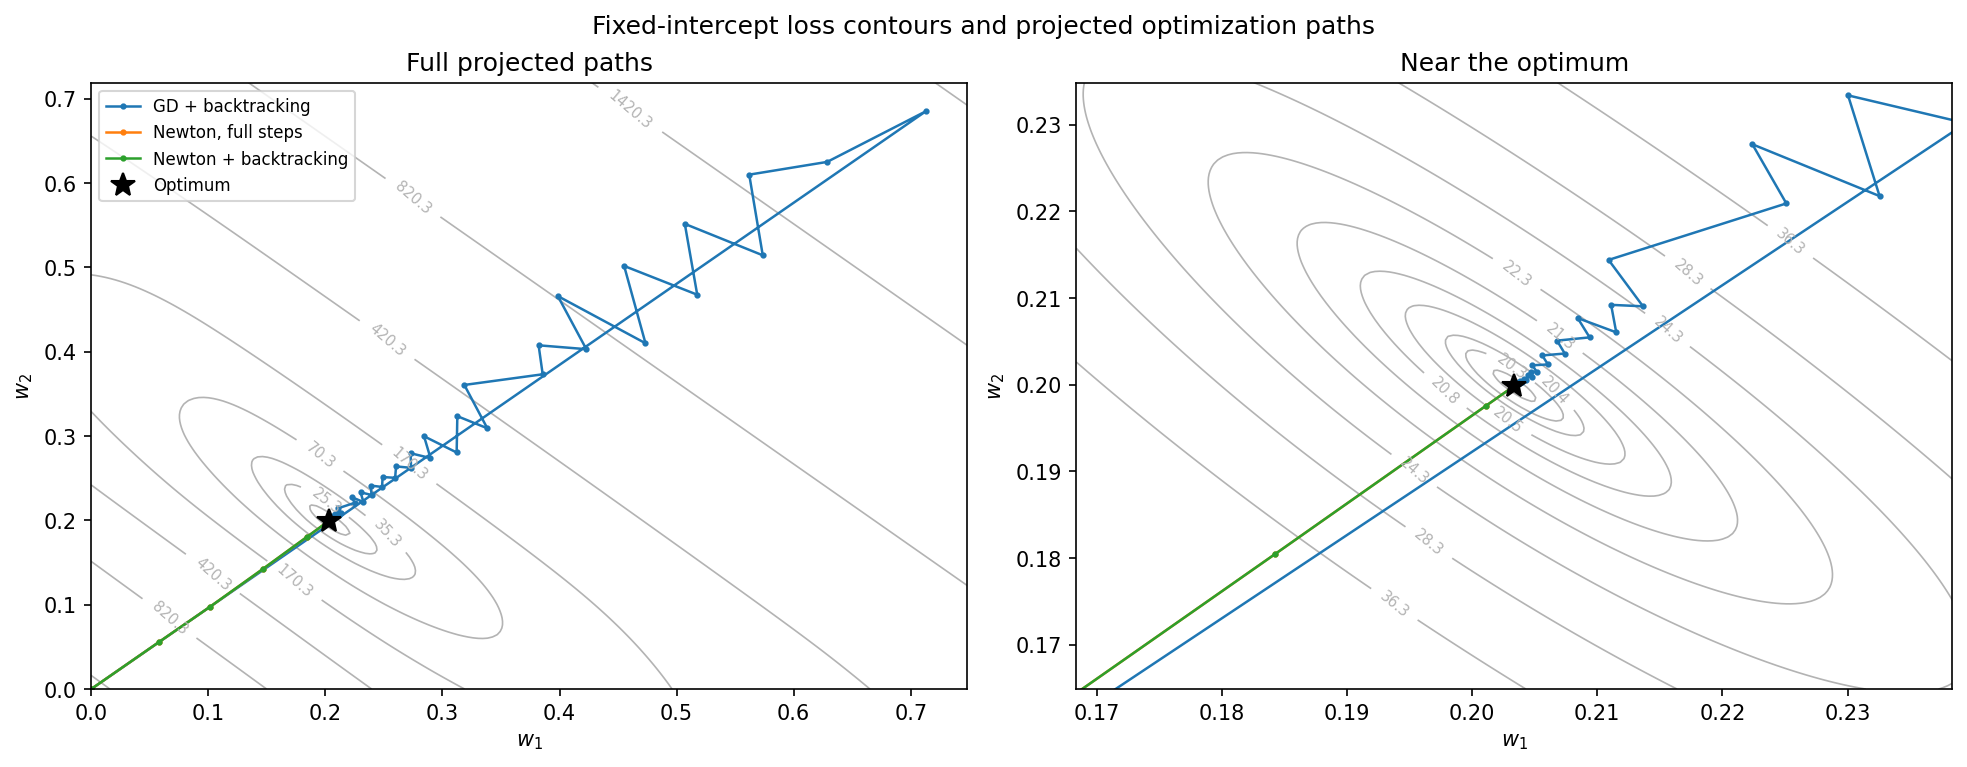

In [12]:
# Part (c) and (d) : Plot paths over loss contours
optimum = to_original(
    runs["Newton + backtracking"]["theta"]
)[0]

minimum_loss = loss(optimum, X, y)

all_paths = np.vstack([
    to_original(result["path"])
    for result in runs.values()
])

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    constrained_layout=True
)

for ax, zoom in zip(axes, [False, True]):

    if zoom:
        limits = (
            optimum[1] - 0.035,
            optimum[1] + 0.035,
            optimum[2] - 0.035,
            optimum[2] + 0.035
        )

        offsets = np.array([
            0.01, 0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8, 16
        ])

    else:
        limits = (
            0,
            max(0.24, 1.05 * all_paths[:, 1].max()),
            0,
            max(0.24, 1.05 * all_paths[:, 2].max())
        )

        offsets = np.array([
            0.1, 1, 5, 15, 50, 150, 400, 800, 1400, 2000
        ])

    w1_grid, w2_grid = np.meshgrid(
        np.linspace(limits[0], limits[1], 180),
        np.linspace(limits[2], limits[3], 180)
    )

    grid_parameters = np.column_stack([
        np.full(w1_grid.size, optimum[0]),
        w1_grid.ravel(),
        w2_grid.ravel()
    ])

    contour_values = np.empty(len(grid_parameters))

    # Evaluate in batches to avoid large temporary arrays.
    for start in range(0, len(grid_parameters), 1000):

        logits = X @ grid_parameters[start:start + 1000].T

        contour_values[start:start + 1000] = (
            np.logaddexp(0, logits)
            - y[:, None] * logits
        ).sum(axis=0)

    contours = ax.contour(
        w1_grid,
        w2_grid,
        contour_values.reshape(w1_grid.shape),
        levels=minimum_loss + offsets,
        colors="0.7",
        linewidths=0.8
    )

    ax.clabel(
        contours,
        fontsize=7,
        fmt="%.1f"
    )

    for name, result in runs.items():

        path = to_original(result["path"])

        ax.plot(
            path[:, 1],
            path[:, 2],
            "-o",
            markersize=2,
            linewidth=1.2,
            label=name
        )

    ax.plot(
        optimum[1],
        optimum[2],
        "k*",
        markersize=12,
        label="Optimum"
    )

    ax.set(
        xlabel="$w_1$",
        ylabel="$w_2$",
        xlim=limits[:2],
        ylim=limits[2:],
        title=(
            "Near the optimum"
            if zoom else "Full projected paths"
        )
    )

axes[0].legend(fontsize=8)

fig.suptitle(
    "Fixed-intercept loss contours and projected optimization paths",
    fontsize=12
)

fig.savefig(
    OUTPUT / "optimization_paths.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Actual loss convergence and intercept evolution
The left plot tracks the true objective gap rather than the fixed-intercept contour slice. Gaps are floored at $10^{-14}$ for the logarithmic axis. The right plot confirms that the intercept changes during optimization.

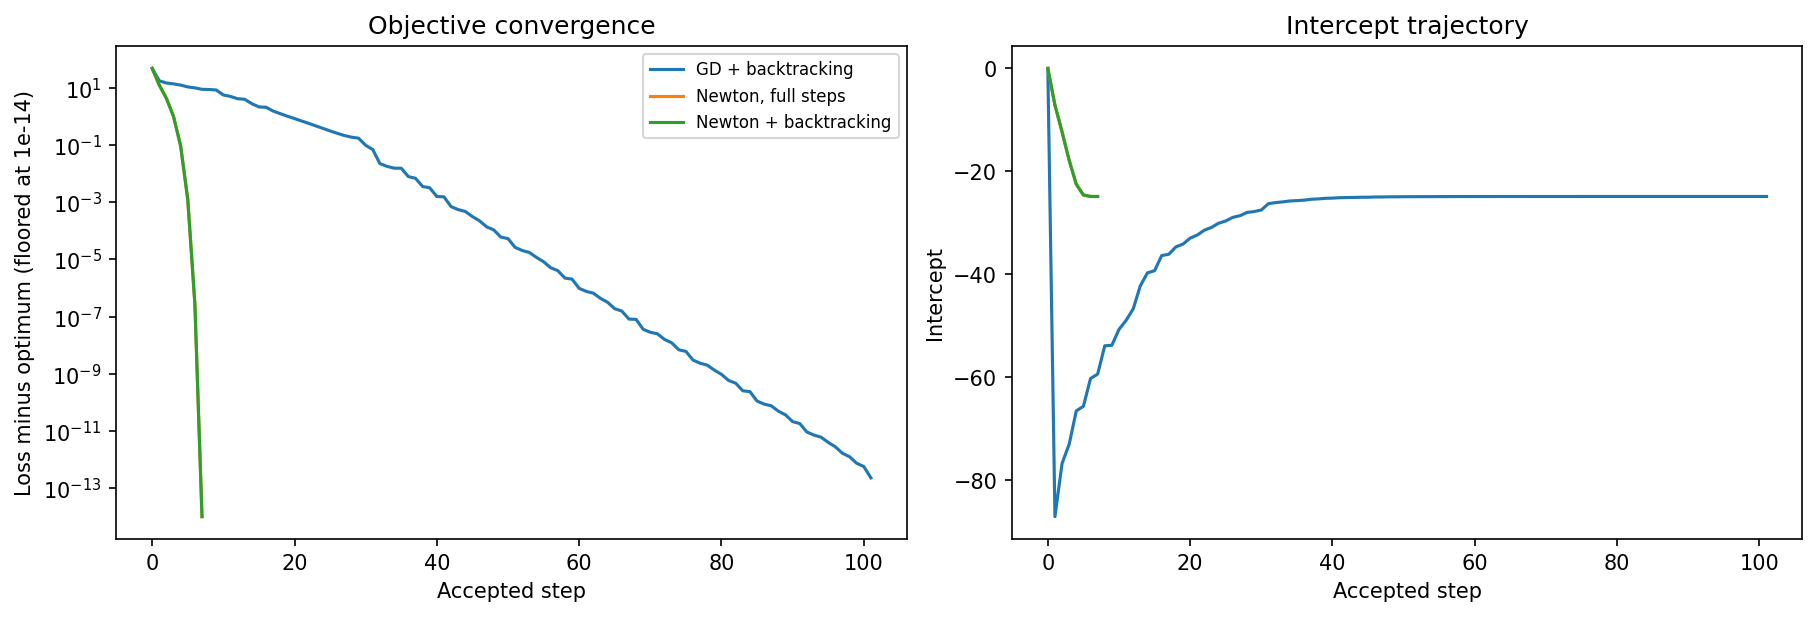

In [13]:
# Plot loss convergence and the intercept
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
    constrained_layout=True
)

for name, result in runs.items():

    objective_gap = np.maximum(
        result["losses"] - minimum_loss,
        1e-14
    )

    axes[0].semilogy(
        objective_gap,
        label=name
    )

    original_path = to_original(result["path"])

    axes[1].plot(
        original_path[:, 0],
        label=name
    )

axes[0].set(
    xlabel="Accepted step",
    ylabel="Loss minus optimum (floored at 1e-14)",
    title="Objective convergence"
)

axes[1].set(
    xlabel="Accepted step",
    ylabel="Intercept",
    title="Intercept trajectory"
)

axes[0].legend(fontsize=8)

fig.savefig(
    OUTPUT / "convergence.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Part (d): robustness from a harder start
This is a separate experiment on the same data, starting at standardized coefficients $(-5,5,5)$. It tests whether backtracking can stabilize Newton away from the zero-start trajectory. Failure is reported honestly rather than silently switching methods.

In [14]:
# (d): Test Newton from a harder starting point
hard_start = np.array([-5.0, 5.0, 5.0])

stress_rows = []

for use_backtracking in [False, True]:

    result = optimize(
        Z,
        y,
        method="newton",
        line_search=use_backtracking,
        initial=hard_start,
        maxiter=100
    )

    stress_rows.append({
        "Backtracking": use_backtracking,
        "Status": result["status"],
        "Accepted steps": result["steps"],
        "Final loss": result["losses"][-1],
        "Total backtrack reductions": int(
            result["backtracks"].sum()
        )
    })

stress_results = pd.DataFrame(stress_rows)

display(stress_results)

,Backtracking,Status,Accepted steps,Final loss,Total backtrack reductions
0,False,singular Hessian,2,5.771414e+06,0
1,True,converged,8,2.025118e+01,4


## Fitted decision boundary
The plotted boundary satisfies $b+w_1x_1+w_2x_2=0$, corresponding to predicted probability $0.5$. This is an additional check of the final fit.

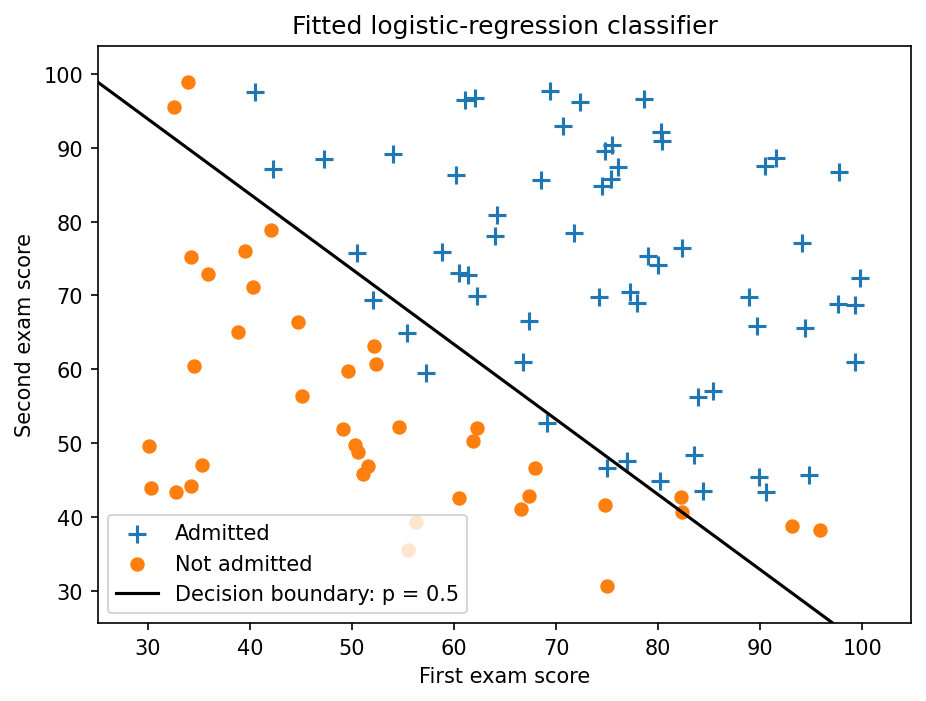

In [15]:
# Plot the fitted decision boundary
theta = to_original(
    runs["Newton + backtracking"]["theta"]
)[0]

exam1_values = np.linspace(
    features[:, 0].min() - 5,
    features[:, 0].max() + 5,
    200
)

exam2_boundary = -(
    theta[0] + theta[1] * exam1_values
) / theta[2]

plt.figure(figsize=(7, 5))

plt.scatter(
    features[admitted, 0],
    features[admitted, 1],
    marker="+",
    s=70,
    label="Admitted"
)

plt.scatter(
    features[not_admitted, 0],
    features[not_admitted, 1],
    marker="o",
    s=35,
    label="Not admitted"
)

plt.plot(
    exam1_values,
    exam2_boundary,
    color="black",
    label="Decision boundary: p = 0.5"
)

plt.xlabel("First exam score")
plt.ylabel("Second exam score")
plt.title("Fitted logistic-regression classifier")

plt.xlim(
    features[:, 0].min() - 5,
    features[:, 0].max() + 5
)

plt.ylim(
    features[:, 1].min() - 5,
    features[:, 1].max() + 5
)

plt.legend()

plt.savefig(
    OUTPUT / "decision_boundary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Export numerical results
The comparison table, stress test, and complete three-dimensional paths are saved as CSV files in the local `results` directory. Figures are saved as PNG files.

In [16]:
# Export results to CSV
comparison.to_csv(
    OUTPUT / "method_comparison.csv",
    index=False
)

stress_results.to_csv(
    OUTPUT / "newton_stress_test.csv",
    index=False
)

filenames = {
    "GD + backtracking": "gd_backtracking_trajectory.csv",
    "Newton, full steps": "newton_full_trajectory.csv",
    "Newton + backtracking": "newton_backtracking_trajectory.csv"
}

for name, history in histories.items():
    history.to_csv(
        OUTPUT / filenames[name]
    )

print("Results saved in:", OUTPUT.resolve())
print()

for file in sorted(OUTPUT.iterdir()):
    print(file.name)

Results saved in: /workspace/work/assignment4_delivery/results

convergence.png
decision_boundary.png
gd_backtracking_trajectory.csv
method_comparison.csv
newton_backtracking_trajectory.csv
newton_full_trajectory.csv
newton_stress_test.csv
optimization_paths.png


## Written answers and conclusions
### (a) Implementation
The custom routine uses the negative gradient and Armijo backtracking. It stores the full parameter vector after every accepted step and uses no built-in optimization routine.

### (b) Agreement with the reference
The estimated gradient-descent coefficients are

$$
\boxed{\hat\theta_{GD}=(-24.86993827,\ 0.20338199,\ 0.19988177)^T}.
$$

The PDF reports $(-24.86874868,0.20337210,0.19987258)^T$. The Euclidean distance to that printed vector is 0.00118967, mainly in the intercept. The distance to a tighter-tolerance TNC estimate is 8.71e-06. All custom methods attain

$$
\boxed{f(\hat\theta)\approx20.25118226,\quad\text{training accuracy}=88.8889\%}.
$$

### (c) Recorded paths
Every initial and accepted three-dimensional vector is saved. Gradient descent follows a zigzagging projected path, whereas Newton approaches the optimum with fewer updates. The fixed-intercept contour slice is not the actual changing-intercept optimization surface; the true loss plot provides the decrease check.

### (d) Newton comparison
|Method|Intercept|w1|w2|Accepted steps|Median ms (51 runs)|
|---|---:|---:|---:|---:|---:|
|GD + backtracking|-24.86993827|0.20338199|0.19988177|101|3.961|
|Newton, full steps|-24.86993268|0.20338195|0.19988172|7|0.247|
|Newton + backtracking|-24.86993268|0.20338195|0.19988172|7|0.268|

**Correct solution:** Both Newton variants reach essentially the same coefficients and loss as gradient descent and TNC.

**Steps:** Newton takes 7 updates versus 101 for gradient descent because it uses curvature information.

**Time:** On this machine the median optimizer times are 3.961 ms for gradient descent, 0.247 ms for full Newton, and 0.268 ms for backtracking Newton. With only three parameters, the Hessian solve is inexpensive. Timing advantages need not generalize to large-dimensional models.

**Backtracking from zero:** Both Newton variants accept full steps throughout, so their paths overlap and both require 7 updates. Backtracking adds an objective check without changing this trajectory. Runtime differences are small and may vary between runs.

**Harder start:** From standardized $(-5,5,5)$, full Newton reports `singular Hessian` after 2 updates, whereas backtracking Newton reports `converged` after 8 updates, with 4 step reductions. Here backtracking improves robustness.

**Scope:** All estimates are in-sample. The shared stopping rule is imposed in standardized coordinates; coefficients and paths are reported in original units. The 99-row loading convention is explicitly chosen to reproduce the reference PDF.
